# Social Media Engagement Analysis

**Project Type:** Data Analytics Internship Project

**Objective:** Analyze social media engagement to measure audience interactions, identify high-performing content, understand posting patterns, and develop data-driven recommendations.

**Dataset:** Synthetic/sample social media dataset containing 1,200 posts from 2025.

**Tools:** Python, pandas, Matplotlib, Google Colab.

**Key Metrics:** Total Engagement, Average Engagement, Engagement Rate, platform performance, content performance, and posting patterns.

**Important Note:** The dataset is synthetic and is used for analytical demonstration. The results should not be interpreted as actual performance data from a real company.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Social_Media_Raw_Data.xlsx to Social_Media_Raw_Data.xlsx


In [ ]:
df = pd.read_excel("Social_Media_Raw_Data.xlsx")

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully.
Number of rows: 1200
Number of columns: 14


In [ ]:
df.head()

,Post_ID,Post_Date,Post_Time,Platform,Content_Type,Theme,Content_Description,Likes,Comments,Shares,Clicks,Reach,Impressions,Followers
0,SM0756,2025-01-01,19:30,Instagram,Carousel,Behind the Scenes,"A closer look at our people, process and daily...",1728,66,129,275,18897,37800,52081
1,SM0849,2025-01-01,19:30,Facebook,Video,Product Promotion,New product highlights and feature updates for...,575,26,87,149,14877,24696,38815
2,SM1029,2025-01-01,19:30,Instagram,Reel,Product Promotion,New product highlights and feature updates for...,1738,120,177,384,35780,41462,52108
3,SM0649,2025-01-01,20:15,Instagram,Image,Product Promotion,New product highlights and feature updates for...,636,34,57,85,18550,23161,52323
4,SM0992,2025-01-01,20:15,Facebook,Image,Tips & Advice,"Useful tips, advice and practical ideas for ou...",458,25,66,100,13670,24639,37789


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Post_ID              1200 non-null   object        
 1   Post_Date            1200 non-null   datetime64[ns]
 2   Post_Time            1200 non-null   object        
 3   Platform             1200 non-null   object        
 4   Content_Type         1200 non-null   object        
 5   Theme                1200 non-null   object        
 6   Content_Description  1200 non-null   object        
 7   Likes                1200 non-null   int64         
 8   Comments             1200 non-null   int64         
 9   Shares               1200 non-null   int64         
 10  Clicks               1200 non-null   int64         
 11  Reach                1200 non-null   int64         
 12  Impressions          1200 non-null   int64         
 13  Followers            1200 non-nul

In [ ]:
print("Missing values by column:")
print(df.isnull().sum())

Missing values by column:
Post_ID                0
Post_Date              0
Post_Time              0
Platform               0
Content_Type           0
Theme                  0
Content_Description    0
Likes                  0
Comments               0
Shares                 0
Clicks                 0
Reach                  0
Impressions            0
Followers              0
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Post_ID values:", df["Post_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Post_ID values: 0


In [ ]:
print(df.columns.tolist())

['Post_ID', 'Post_Date', 'Post_Time', 'Platform', 'Content_Type', 'Theme', 'Content_Description', 'Likes', 'Comments', 'Shares', 'Clicks', 'Reach', 'Impressions', 'Followers']


In [ ]:
print(df.dtypes)

Post_ID                        object
Post_Date              datetime64[ns]
Post_Time                      object
Platform                       object
Content_Type                   object
Theme                          object
Content_Description            object
Likes                           int64
Comments                        int64
Shares                          int64
Clicks                          int64
Reach                           int64
Impressions                     int64
Followers                       int64
dtype: object


In [ ]:
numeric_columns = [
    "Likes", "Comments", "Shares", "Clicks",
    "Reach", "Impressions", "Followers"
]

print(df[numeric_columns].describe())
print("\nNegative values by column:")
print((df[numeric_columns] < 0).sum())

             Likes     Comments       Shares       Clicks         Reach  \
count  1200.000000  1200.000000  1200.000000  1200.000000   1200.000000   
mean    962.081667    55.298333   111.929167   150.945000  22429.975833   
std     680.705068    43.692698    84.768010   112.325373   8964.724955   
min      83.000000     5.000000     9.000000     9.000000   6830.000000   
25%     446.750000    24.000000    51.000000    69.750000  14896.000000   
50%     773.000000    43.000000    89.000000   119.500000  21287.500000   
75%    1284.000000    73.000000   148.000000   206.250000  28608.000000   
max    4105.000000   338.000000   686.000000   737.000000  48782.000000   

         Impressions     Followers  
count    1200.000000   1200.000000  
mean    36396.386667  49720.440000  
std     16129.353763   7947.726736  
min      8173.000000  34982.000000  
25%     23834.750000  41458.250000  
50%     33362.000000  52443.500000  
75%     46379.000000  56416.250000  
max    100668.000000  63273.

In [ ]:
print("Post_Date examples:")
print(df["Post_Date"].head(10))

print("\nPost_Time examples:")
print(df["Post_Time"].head(10))

Post_Date examples:
0   2025-01-01
1   2025-01-01
2   2025-01-01
3   2025-01-01
4   2025-01-01
5   2025-01-01
6   2025-01-01
7   2025-01-01
8   2025-01-02
9   2025-01-02
Name: Post_Date, dtype: datetime64[ns]

Post_Time examples:
0    19:30
1    19:30
2    19:30
3    20:15
4    20:15
5    21:30
6    21:30
7    21:45
8    12:30
9    14:15
Name: Post_Time, dtype: object


In [ ]:
for column in ["Platform", "Content_Type", "Theme"]:
    print(f"\n{column}:")
    print(sorted(df[column].dropna().astype(str).unique()))


Platform:
['Facebook', 'Instagram']

Content_Type:
['Carousel', 'Image', 'Reel', 'Story', 'Video']

Theme:
['Announcements', 'Behind the Scenes', 'Customer Stories', 'Educational', 'Events', 'Product Promotion', 'Seasonal', 'Tips & Advice']


In [ ]:
test_dates = pd.to_datetime(df["Post_Date"], errors="coerce")

print("Successfully parsed dates:", test_dates.notna().sum())
print("Unparsed dates:", test_dates.isna().sum())
print("Date range:", test_dates.min(), "to", test_dates.max())

Successfully parsed dates: 1200
Unparsed dates: 0
Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00


In [ ]:
unparsed_dates = df.loc[
    test_dates.isna() & df["Post_Date"].notna(),
    "Post_Date"
]

print(unparsed_dates.head(20))

Series([], Name: Post_Date, dtype: datetime64[ns])


In [ ]:
print("Number of unique time values:", df["Post_Time"].nunique())
print("\nSample time values:")
print(df["Post_Time"].drop_duplicates().head(20).tolist())

Number of unique time values: 56

Sample time values:
['19:30', '20:15', '21:30', '21:45', '12:30', '14:15', '16:45', '11:00', '14:30', '17:45', '18:30', '19:45', '10:30', '17:00', '20:30', '21:00', '16:30', '20:45', '18:00', '21:15']


In [ ]:
expected_columns = [
    "Post_ID", "Post_Date", "Post_Time", "Platform",
    "Content_Type", "Theme", "Content_Description",
    "Likes", "Comments", "Shares", "Clicks",
    "Reach", "Impressions", "Followers"
]

print("Missing expected columns:",
      [col for col in expected_columns if col not in df.columns])

print("Unexpected columns:",
      [col for col in df.columns if col not in expected_columns])

Missing expected columns: []
Unexpected columns: []


In [ ]:
clean_df = df.copy()

print("Working copy created.")
print("Rows:", clean_df.shape[0])
print("Columns:", clean_df.shape[1])

Working copy created.
Rows: 1200
Columns: 14


In [ ]:
parsed_time = pd.to_datetime(
    clean_df["Post_Time"],
    format="%H:%M",
    errors="coerce"
)

print("Successfully parsed times:", parsed_time.notna().sum())
print("Unparsed times:", parsed_time.isna().sum())

Successfully parsed times: 1200
Unparsed times: 0


In [ ]:
clean_df["Post_Hour"] = parsed_time.dt.hour

print(clean_df[["Post_Time", "Post_Hour"]].head(10))

  Post_Time  Post_Hour
0     19:30         19
1     19:30         19
2     19:30         19
3     20:15         20
4     20:15         20
5     21:30         21
6     21:30         21
7     21:45         21
8     12:30         12
9     14:15         14


In [ ]:
clean_df["Day_of_Week"] = clean_df["Post_Date"].dt.day_name()

print(clean_df["Day_of_Week"].value_counts())

Day_of_Week
Sunday       184
Thursday     181
Monday       176
Tuesday      176
Wednesday    172
Saturday     160
Friday       151
Name: count, dtype: int64


In [ ]:
clean_df["Month"] = clean_df["Post_Date"].dt.month_name()
clean_df["Month_Number"] = clean_df["Post_Date"].dt.month

print(clean_df[["Post_Date", "Month", "Month_Number"]].head(10))

   Post_Date    Month  Month_Number
0 2025-01-01  January             1
1 2025-01-01  January             1
2 2025-01-01  January             1
3 2025-01-01  January             1
4 2025-01-01  January             1
5 2025-01-01  January             1
6 2025-01-01  January             1
7 2025-01-01  January             1
8 2025-01-02  January             1
9 2025-01-02  January             1


In [ ]:
clean_df["Time_Period"] = np.select(
    [
        clean_df["Post_Hour"] < 12,
        clean_df["Post_Hour"] < 17
    ],
    [
        "Morning",
        "Afternoon"
    ],
    default="Evening"
)

print(clean_df["Time_Period"].value_counts())

Time_Period
Evening      800
Afternoon    219
Morning      181
Name: count, dtype: int64


In [ ]:
engagement_columns = ["Likes", "Comments", "Shares", "Clicks"]

clean_df["Total_Engagement"] = clean_df[engagement_columns].sum(axis=1)

print(clean_df[
    ["Post_ID", "Likes", "Comments", "Shares", "Clicks", "Total_Engagement"]
].head(10))

  Post_ID  Likes  Comments  Shares  Clicks  Total_Engagement
0  SM0756   1728        66     129     275              2198
1  SM0849    575        26      87     149               837
2  SM1029   1738       120     177     384              2419
3  SM0649    636        34      57      85               812
4  SM0992    458        25      66     100               649
5  SM0447    707        31     145     119              1002
6  SM1165   1136        47     139     162              1484
7  SM0678    179        10      18      29               236
8  SM0264    570        14      51      62               697
9  SM0064   1187        75     171     241              1674


In [ ]:
clean_df["Engagement_Rate"] = (
    clean_df["Total_Engagement"]
    .div(clean_df["Reach"].replace(0, np.nan))
    .mul(100)
)

print(clean_df[
    ["Post_ID", "Total_Engagement", "Reach", "Engagement_Rate"]
].head(10))

  Post_ID  Total_Engagement  Reach  Engagement_Rate
0  SM0756              2198  18897        11.631476
1  SM0849               837  14877         5.626134
2  SM1029              2419  35780         6.760760
3  SM0649               812  18550         4.377358
4  SM0992               649  13670         4.747623
5  SM0447              1002  18143         5.522791
6  SM1165              1484  30903         4.802123
7  SM0678               236  10515         2.244413
8  SM0264               697  17210         4.049971
9  SM0064              1674  24966         6.705119


In [ ]:
print("Total posts:", len(clean_df))
print("Total engagement:", clean_df["Total_Engagement"].sum())
print("Average engagement:", clean_df["Total_Engagement"].mean())
print("Average engagement rate (%):", clean_df["Engagement_Rate"].mean())

Total posts: 1200
Total engagement: 1536305
Average engagement: 1280.2541666666666
Average engagement rate (%): 5.246133675046402


In [ ]:
derived_columns = [
    "Post_Hour", "Day_of_Week", "Month",
    "Month_Number", "Time_Period",
    "Total_Engagement", "Engagement_Rate"
]

print(clean_df[derived_columns].isna().sum())

Post_Hour           0
Day_of_Week         0
Month               0
Month_Number        0
Time_Period         0
Total_Engagement    0
Engagement_Rate     0
dtype: int64


In [ ]:
print("Cleaned dataset shape:", clean_df.shape)
display(clean_df.head())

Cleaned dataset shape: (1200, 21)


,Post_ID,Post_Date,Post_Time,Platform,Content_Type,Theme,Content_Description,Likes,Comments,Shares,...,Reach,Impressions,Followers,Post_Hour,Day_of_Week,Month,Month_Number,Time_Period,Total_Engagement,Engagement_Rate
0,SM0756,2025-01-01,19:30,Instagram,Carousel,Behind the Scenes,"A closer look at our people, process and daily...",1728,66,129,...,18897,37800,52081,19,Wednesday,January,1,Evening,2198,11.631476
1,SM0849,2025-01-01,19:30,Facebook,Video,Product Promotion,New product highlights and feature updates for...,575,26,87,...,14877,24696,38815,19,Wednesday,January,1,Evening,837,5.626134
2,SM1029,2025-01-01,19:30,Instagram,Reel,Product Promotion,New product highlights and feature updates for...,1738,120,177,...,35780,41462,52108,19,Wednesday,January,1,Evening,2419,6.760760
3,SM0649,2025-01-01,20:15,Instagram,Image,Product Promotion,New product highlights and feature updates for...,636,34,57,...,18550,23161,52323,20,Wednesday,January,1,Evening,812,4.377358
4,SM0992,2025-01-01,20:15,Facebook,Image,Tips & Advice,"Useful tips, advice and practical ideas for ou...",458,25,66,...,13670,24639,37789,20,Wednesday,January,1,Evening,649,4.747623


In [ ]:
platform_analysis = clean_df.groupby("Platform").agg(
    Posts=("Post_ID", "count"),
    Total_Engagement=("Total_Engagement", "sum"),
    Average_Engagement=("Total_Engagement", "mean"),
    Average_Engagement_Rate=("Engagement_Rate", "mean")
).reset_index()

platform_analysis["Average_Engagement_Rate"] = (
    platform_analysis["Average_Engagement_Rate"].round(2)
)

display(platform_analysis)

,Platform,Posts,Total_Engagement,Average_Engagement,Average_Engagement_Rate
0,Facebook,495,307521,621.254545,4.12
1,Instagram,705,1228784,1742.956028,6.04


In [ ]:
content_analysis = clean_df.groupby("Content_Type").agg(
    Posts=("Post_ID", "count"),
    Total_Engagement=("Total_Engagement", "sum"),
    Average_Engagement=("Total_Engagement", "mean"),
    Average_Engagement_Rate=("Engagement_Rate", "mean")
).reset_index()

content_analysis = content_analysis.sort_values(
    "Average_Engagement", ascending=False
)

display(content_analysis.round(2))

,Content_Type,Posts,Total_Engagement,Average_Engagement,Average_Engagement_Rate
2,Reel,364,684674,1880.97,6.59
4,Video,180,252175,1400.97,5.49
0,Carousel,216,268011,1240.79,5.25
1,Image,301,247207,821.29,4.22
3,Story,139,84238,606.03,3.62


In [ ]:
theme_analysis = clean_df.groupby("Theme").agg(
    Posts=("Post_ID", "count"),
    Total_Engagement=("Total_Engagement", "sum"),
    Average_Engagement=("Total_Engagement", "mean"),
    Average_Engagement_Rate=("Engagement_Rate", "mean")
).reset_index()

theme_analysis = theme_analysis.sort_values(
    "Average_Engagement", ascending=False
)

display(theme_analysis.round(2))

,Theme,Posts,Total_Engagement,Average_Engagement,Average_Engagement_Rate
1,Behind the Scenes,155,216927,1399.53,5.54
4,Events,146,200771,1375.14,5.60
6,Seasonal,179,239573,1338.40,5.37
2,Customer Stories,134,177686,1326.01,5.66
7,Tips & Advice,154,193336,1255.43,5.30
3,Educational,134,166266,1240.79,5.17
5,Product Promotion,140,173611,1240.08,5.10
0,Announcements,158,168135,1064.15,4.28


In [ ]:
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

day_analysis = clean_df.groupby("Day_of_Week").agg(
    Posts=("Post_ID", "count"),
    Total_Engagement=("Total_Engagement", "sum"),
    Average_Engagement=("Total_Engagement", "mean"),
    Average_Engagement_Rate=("Engagement_Rate", "mean")
).reindex(day_order).reset_index()

display(day_analysis.round(2))

,Day_of_Week,Posts,Total_Engagement,Average_Engagement,Average_Engagement_Rate
0,Monday,176,206435,1172.93,4.87
1,Tuesday,176,233695,1327.81,5.28
2,Wednesday,172,239987,1395.27,5.43
3,Thursday,181,223643,1235.60,5.02
4,Friday,151,179669,1189.86,4.96
5,Saturday,160,202562,1266.01,5.48
6,Sunday,184,250314,1360.40,5.64


In [ ]:
hour_analysis = clean_df.groupby("Post_Hour").agg(
    Posts=("Post_ID", "count"),
    Total_Engagement=("Total_Engagement", "sum"),
    Average_Engagement=("Total_Engagement", "mean"),
    Average_Engagement_Rate=("Engagement_Rate", "mean")
).reindex(range(24), fill_value=0).reset_index()

display(hour_analysis.round(2))

,Post_Hour,Posts,Total_Engagement,Average_Engagement,Average_Engagement_Rate
0,0,0,0,0.00,0.00
1,1,0,0,0.00,0.00
2,2,0,0,0.00,0.00
3,3,0,0,0.00,0.00
4,4,0,0,0.00,0.00
5,5,0,0,0.00,0.00
6,6,0,0,0.00,0.00
7,7,0,0,0.00,0.00
8,8,36,37489,1041.36,4.20
9,9,55,70978,1290.51,4.87


In [ ]:
period_order = ["Morning", "Afternoon", "Evening"]

period_analysis = clean_df.groupby("Time_Period").agg(
    Posts=("Post_ID", "count"),
    Total_Engagement=("Total_Engagement", "sum"),
    Average_Engagement=("Total_Engagement", "mean"),
    Average_Engagement_Rate=("Engagement_Rate", "mean")
).reindex(period_order).reset_index()

display(period_analysis.round(2))

,Time_Period,Posts,Total_Engagement,Average_Engagement,Average_Engagement_Rate
0,Morning,181,199721,1103.43,4.51
1,Afternoon,219,249650,1139.95,4.81
2,Evening,800,1086934,1358.67,5.53


In [ ]:
monthly_analysis = clean_df.groupby(
    ["Month_Number", "Month"]
).agg(
    Posts=("Post_ID", "count"),
    Total_Engagement=("Total_Engagement", "sum"),
    Average_Engagement=("Total_Engagement", "mean"),
    Average_Engagement_Rate=("Engagement_Rate", "mean")
).reset_index().sort_values("Month_Number")

display(monthly_analysis.round(2))

,Month_Number,Month,Posts,Total_Engagement,Average_Engagement,Average_Engagement_Rate
0,1,January,95,110377,1161.86,5.22
1,2,February,100,131065,1310.65,5.36
2,3,March,76,94121,1238.43,5.27
3,4,April,110,130486,1186.24,5.13
4,5,May,116,151883,1309.34,5.49
5,6,June,106,140731,1327.65,5.51
6,7,July,85,109209,1284.81,5.00
7,8,August,115,142020,1234.96,5.00
8,9,September,95,120374,1267.09,5.16
9,10,October,103,134044,1301.40,5.13


In [ ]:
top_10_engagement = clean_df.nlargest(
    10, "Total_Engagement"
)[[
    "Post_ID", "Platform", "Content_Type", "Theme",
    "Post_Date", "Total_Engagement", "Engagement_Rate"
]]

display(top_10_engagement)

,Post_ID,Platform,Content_Type,Theme,Post_Date,Total_Engagement,Engagement_Rate
109,SM0382,Instagram,Reel,Customer Stories,2025-02-05,5374,14.645845
988,SM1133,Instagram,Reel,Behind the Scenes,2025-10-29,5209,12.343894
1037,SM1141,Instagram,Reel,Customer Stories,2025-11-12,5190,14.412663
633,SM0069,Instagram,Reel,Product Promotion,2025-07-10,4908,13.046599
846,SM0128,Instagram,Reel,Events,2025-09-14,4822,10.652587
1020,SM0716,Instagram,Reel,Seasonal,2025-11-08,4753,10.639060
391,SM0428,Instagram,Reel,Seasonal,2025-05-04,4672,10.229686
666,SM1171,Instagram,Reel,Product Promotion,2025-07-21,4641,13.142469
568,SM0189,Instagram,Reel,Customer Stories,2025-06-21,4637,10.488577
921,SM1118,Instagram,Reel,Behind the Scenes,2025-10-09,4476,10.253356


In [ ]:
top_10_rate = clean_df.nlargest(
    10, "Engagement_Rate"
)[[
    "Post_ID", "Platform", "Content_Type", "Theme",
    "Post_Date", "Total_Engagement", "Engagement_Rate"
]]

display(top_10_rate)

,Post_ID,Platform,Content_Type,Theme,Post_Date,Total_Engagement,Engagement_Rate
20,SM0721,Instagram,Reel,Tips & Advice,2025-01-05,4402,15.294813
109,SM0382,Instagram,Reel,Customer Stories,2025-02-05,5374,14.645845
1037,SM1141,Instagram,Reel,Customer Stories,2025-11-12,5190,14.412663
666,SM1171,Instagram,Reel,Product Promotion,2025-07-21,4641,13.142469
633,SM0069,Instagram,Reel,Product Promotion,2025-07-10,4908,13.046599
1113,SM0813,Instagram,Reel,Educational,2025-12-06,3880,12.400128
988,SM1133,Instagram,Reel,Behind the Scenes,2025-10-29,5209,12.343894
916,SM0228,Instagram,Carousel,Events,2025-10-07,2530,12.229312
544,SM0540,Instagram,Carousel,Tips & Advice,2025-06-13,3862,11.999379
796,SM0642,Instagram,Video,Educational,2025-08-30,2503,11.972067


In [ ]:
print("Platform post total:", platform_analysis["Posts"].sum())
print("Content-type post total:", content_analysis["Posts"].sum())
print("Theme post total:", theme_analysis["Posts"].sum())
print("Day post total:", day_analysis["Posts"].sum())
print("Hour post total:", hour_analysis["Posts"].sum())
print("Time-period post total:", period_analysis["Posts"].sum())
print("Monthly post total:", monthly_analysis["Posts"].sum())

print("\nExpected posts: 1200")
print("Expected total engagement:", clean_df["Total_Engagement"].sum())

Platform post total: 1200
Content-type post total: 1200
Theme post total: 1200
Day post total: 1200
Hour post total: 1200
Time-period post total: 1200
Monthly post total: 1200

Expected posts: 1200
Expected total engagement: 1536305


In [ ]:
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

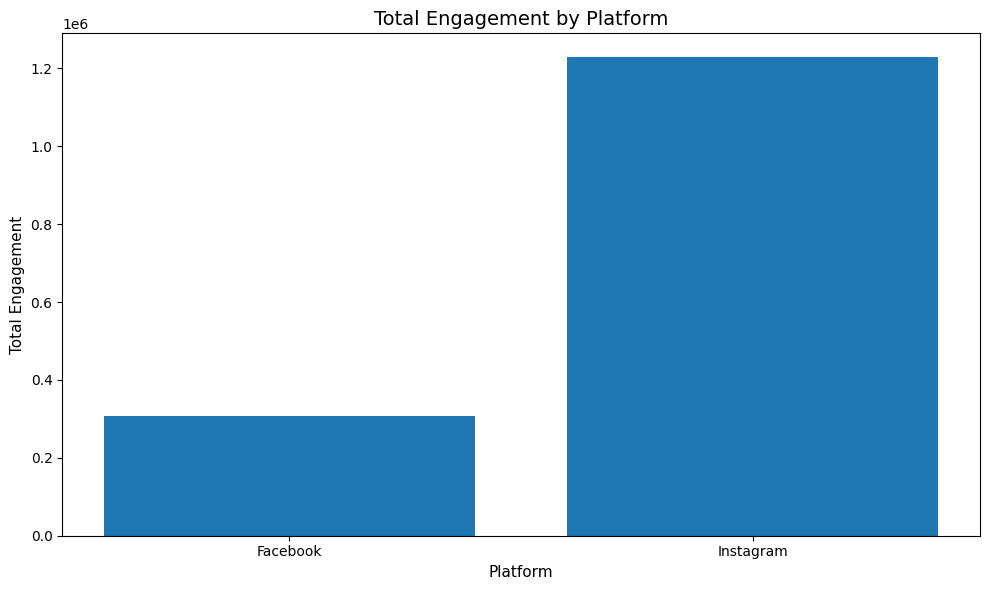

In [ ]:
plt.figure()
plt.bar(
    platform_analysis["Platform"],
    platform_analysis["Total_Engagement"]
)
plt.title("Total Engagement by Platform")
plt.xlabel("Platform")
plt.ylabel("Total Engagement")
plt.tight_layout()
plt.show()

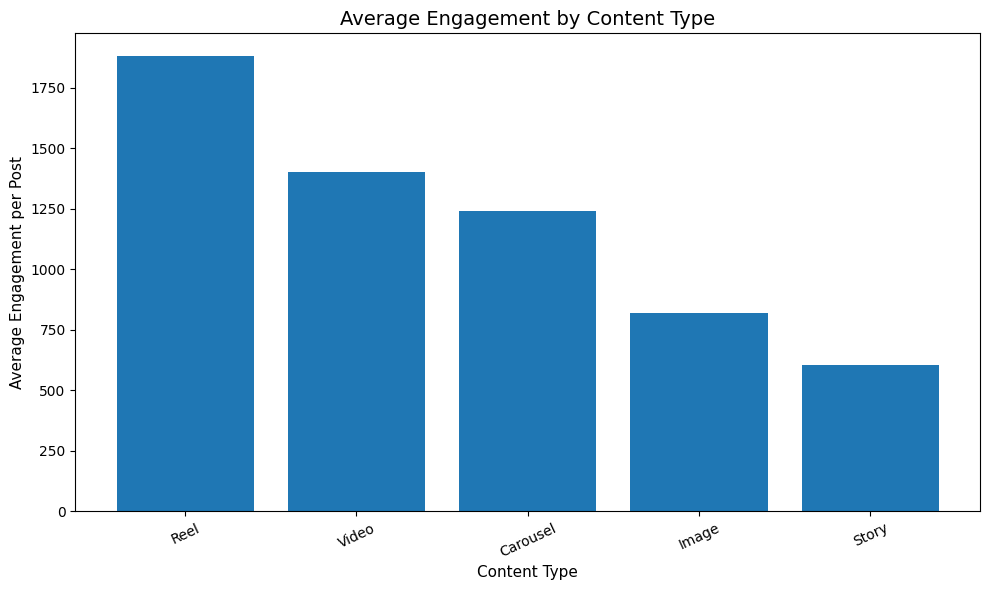

In [ ]:
plt.figure()
plt.bar(
    content_analysis["Content_Type"],
    content_analysis["Average_Engagement"]
)
plt.title("Average Engagement by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Average Engagement per Post")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

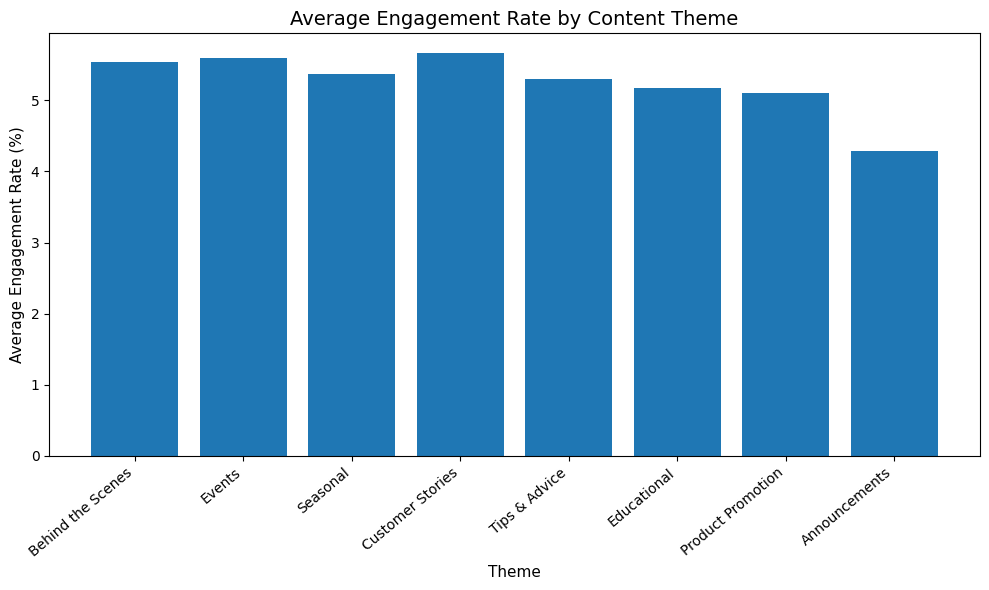

In [ ]:
plt.figure()
plt.bar(
    theme_analysis["Theme"],
    theme_analysis["Average_Engagement_Rate"]
)
plt.title("Average Engagement Rate by Content Theme")
plt.xlabel("Theme")
plt.ylabel("Average Engagement Rate (%)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

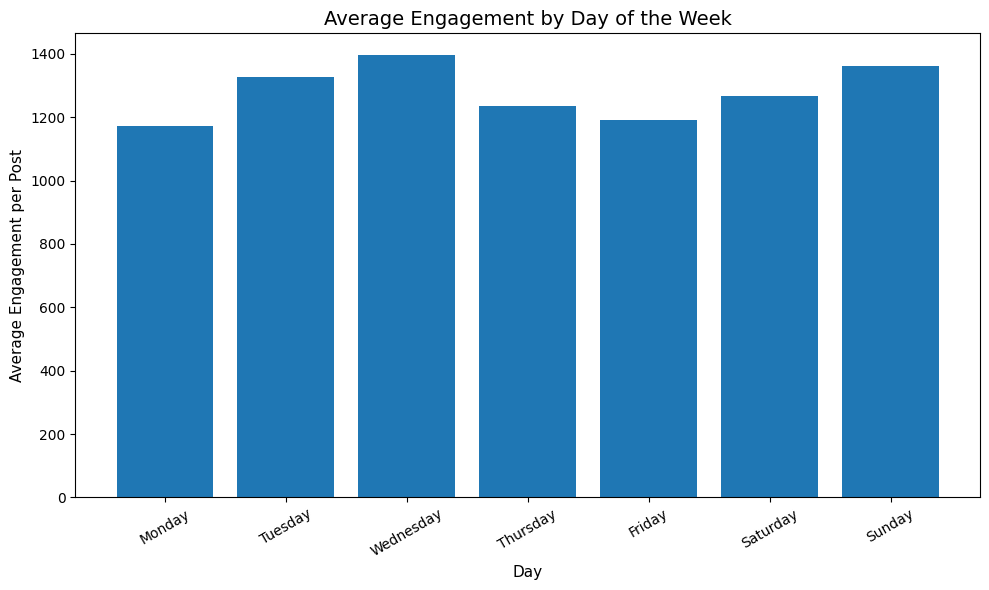

In [ ]:
plt.figure()
plt.bar(
    day_analysis["Day_of_Week"],
    day_analysis["Average_Engagement"]
)
plt.title("Average Engagement by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average Engagement per Post")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

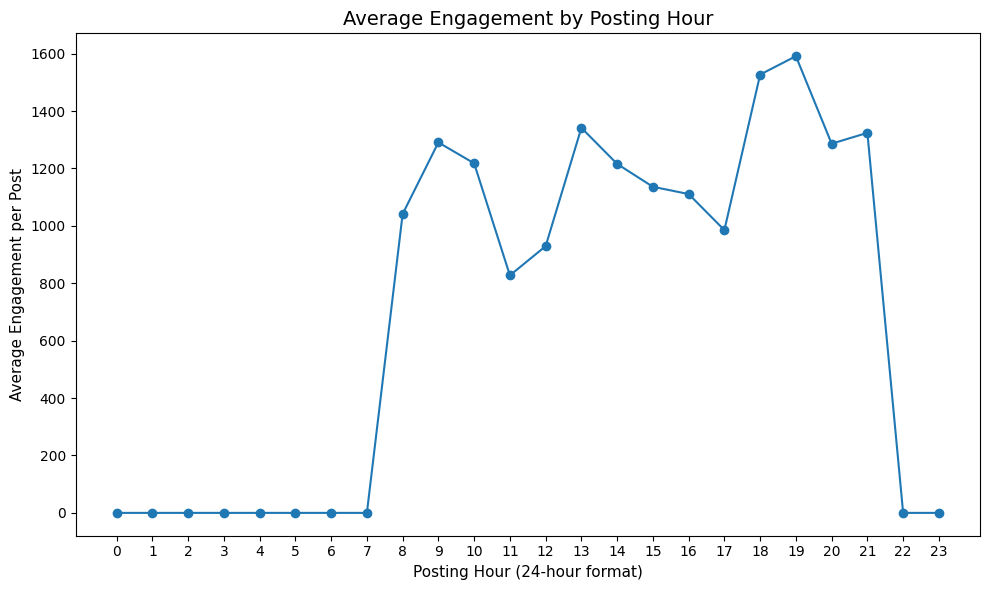

In [ ]:
plt.figure()
plt.plot(
    hour_analysis["Post_Hour"],
    hour_analysis["Average_Engagement"],
    marker="o"
)
plt.title("Average Engagement by Posting Hour")
plt.xlabel("Posting Hour (24-hour format)")
plt.ylabel("Average Engagement per Post")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

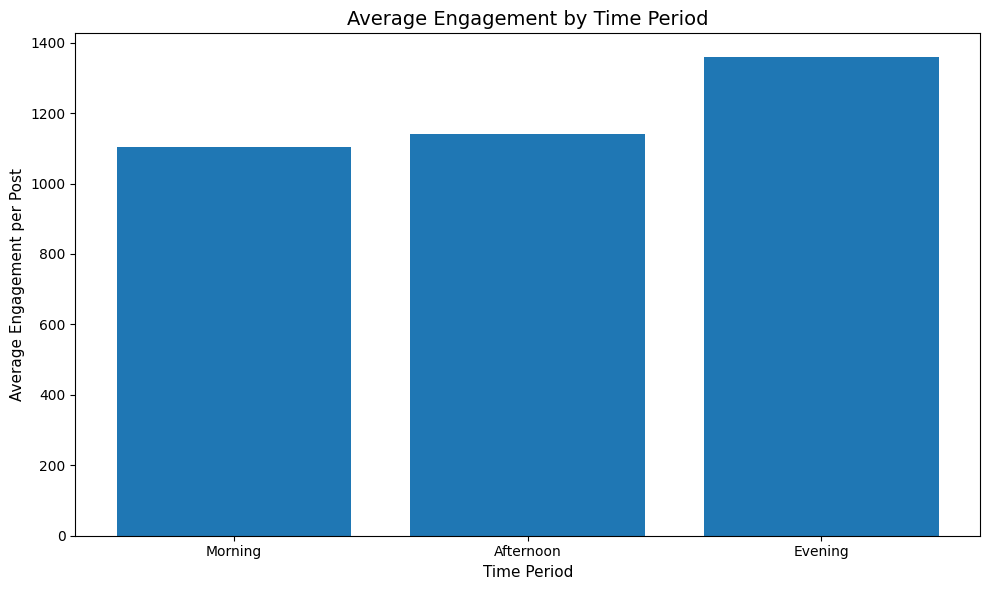

In [ ]:
plt.figure()
plt.bar(
    period_analysis["Time_Period"],
    period_analysis["Average_Engagement"]
)
plt.title("Average Engagement by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Average Engagement per Post")
plt.tight_layout()
plt.show()

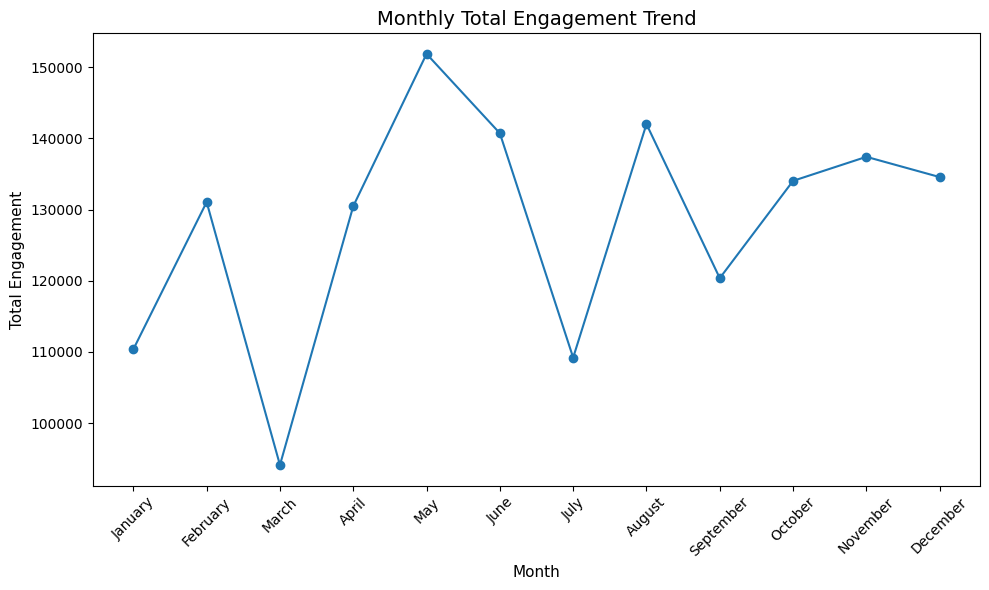

In [ ]:
plt.figure()
plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Total_Engagement"],
    marker="o"
)
plt.title("Monthly Total Engagement Trend")
plt.xlabel("Month")
plt.ylabel("Total Engagement")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

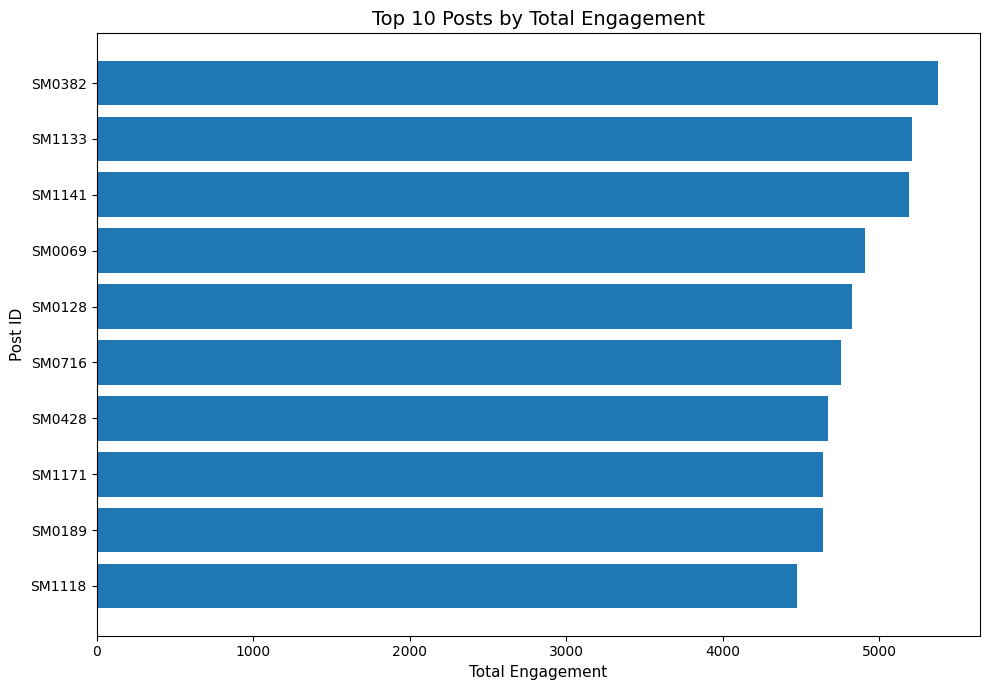

In [ ]:
top_posts_chart = top_10_engagement.sort_values(
    "Total_Engagement", ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_posts_chart["Post_ID"],
    top_posts_chart["Total_Engagement"]
)
plt.title("Top 10 Posts by Total Engagement")
plt.xlabel("Total Engagement")
plt.ylabel("Post ID")
plt.tight_layout()
plt.show()

In [ ]:
import os

chart_folder = "Python_Charts"
os.makedirs(chart_folder, exist_ok=True)

# Recreate and save each chart using the same analysis tables.
charts = [
    ("platform_engagement.png", platform_analysis, "Platform",
     "Total_Engagement", "Total Engagement by Platform", "bar"),
    ("content_type_engagement.png", content_analysis, "Content_Type",
     "Average_Engagement", "Average Engagement by Content Type", "bar"),
    ("theme_engagement_rate.png", theme_analysis, "Theme",
     "Average_Engagement_Rate", "Average Engagement Rate by Theme", "bar"),
    ("day_engagement.png", day_analysis, "Day_of_Week",
     "Average_Engagement", "Average Engagement by Day", "bar"),
    ("hour_engagement.png", hour_analysis, "Post_Hour",
     "Average_Engagement", "Average Engagement by Posting Hour", "line"),
    ("period_engagement.png", period_analysis, "Time_Period",
     "Average_Engagement", "Average Engagement by Time Period", "bar"),
    ("monthly_engagement.png", monthly_analysis, "Month",
     "Total_Engagement", "Monthly Total Engagement", "line"),
    ("top_10_posts.png", top_10_engagement.sort_values("Total_Engagement"),
     "Post_ID", "Total_Engagement", "Top 10 Posts by Total Engagement", "bar")
]

for filename, data, x_col, y_col, title, chart_type in charts:
    plt.figure(figsize=(10, 6))

    if chart_type == "line":
        plt.plot(data[x_col], data[y_col], marker="o")
    elif filename == "top_10_posts.png":
        plt.barh(data[x_col], data[y_col])
    else:
        plt.bar(data[x_col], data[y_col])

    plt.title(title)
    plt.xlabel(x_col.replace("_", " "))
    plt.ylabel(y_col.replace("_", " "))
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(chart_folder, filename), dpi=150)
    plt.close()

print("Saved", len(charts), "charts in:", chart_folder)

Saved 8 charts in: Python_Charts


In [ ]:
import shutil
from google.colab import files

shutil.make_archive("Python_Charts", "zip", chart_folder)
files.download("Python_Charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
clean_df.to_csv("Social_Media_Clean_Data.csv", index=False)
print("Cleaned dataset exported.")

Cleaned dataset exported.


In [ ]:
with pd.ExcelWriter("Python_Analysis_Output.xlsx", engine="openpyxl") as writer:
    platform_analysis.to_excel(writer, sheet_name="Platform Analysis", index=False)
    content_analysis.to_excel(writer, sheet_name="Content Analysis", index=False)
    theme_analysis.to_excel(writer, sheet_name="Theme Analysis", index=False)
    day_analysis.to_excel(writer, sheet_name="Day Analysis", index=False)
    hour_analysis.to_excel(writer, sheet_name="Hour Analysis", index=False)
    period_analysis.to_excel(writer, sheet_name="Time Period Analysis", index=False)
    monthly_analysis.to_excel(writer, sheet_name="Monthly Analysis", index=False)
    top_10_engagement.to_excel(writer, sheet_name="Top 10 Engagement", index=False)
    top_10_rate.to_excel(writer, sheet_name="Top 10 Engagement Rate", index=False)

print("Analysis tables exported.")

Analysis tables exported.


In [ ]:
from google.colab import files

files.download("Social_Media_Clean_Data.csv")
files.download("Python_Analysis_Output.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

for filename in [
    "Social_Media_Clean_Data.csv",
    "Python_Analysis_Output.xlsx"
]:
    print(filename, "—", os.path.getsize(filename), "bytes")

Social_Media_Clean_Data.csv — 235632 bytes
Python_Analysis_Output.xlsx — 13516 bytes


In [ ]:
export_check = pd.read_csv("Social_Media_Clean_Data.csv")

print("Rows:", export_check.shape[0])
print("Columns:", export_check.shape[1])
print("Missing values:", export_check.isna().sum().sum())

Rows: 1200
Columns: 21
Missing values: 0


In [ ]:
with pd.ExcelFile("Python_Analysis_Output.xlsx") as workbook:
    print(workbook.sheet_names)

['Platform Analysis', 'Content Analysis', 'Theme Analysis', 'Day Analysis', 'Hour Analysis', 'Time Period Analysis', 'Monthly Analysis', 'Top 10 Engagement', 'Top 10 Engagement Rate']
